# 02 · Portafolios y backtest walk-forward

**Bloque 2.** Objetivo: comparar cuatro formas de repartir el capital entre las emisoras del universo
(igual ponderado, mínima varianza, máximo Sharpe y HRP) con un backtest *walk-forward* que incluye
costos de transacción, y medirlas contra el NAFTRAC.

La pregunta no es cuál estrategia ganó, sino si alguna mejora de forma creíble a las alternativas simples
una vez que se descuentan costos y se reconocen las limitaciones de los datos.

In [1]:
import sys
from pathlib import Path

# Permite importar `src` al ejecutar desde la carpeta notebooks/
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import functools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import backtest, config, data, metrics, plots, portfolios

plots.set_style()
TD = config.TRADING_DAYS

## 1. Datos

Mismo universo y misma limpieza que en el notebook 01: 31 emisoras de la muestra del IPC de sep-2026
(sin AMXB, excluida por calidad de datos) y NAFTRAC como benchmark con dividendos.
Para portafolios se usan retornos **simples**, que sí se suman entre activos.

In [2]:
prices = data.clean_prices(data.download_prices())
simple_rets = data.compute_returns(prices, log=False)
stock_rets, bench_rets = data.split_benchmark(simple_rets)

print(f"Emisoras: {stock_rets.shape[1]} | Benchmark: {bench_rets.name}")
print(f"Retornos diarios: {len(stock_rets)} | {stock_rets.index.min().date()} → {stock_rets.index.max().date()}")

Emisoras: 31 | Benchmark: NAFTRAC.MX
Retornos diarios: 2824 | 2015-07-20 → 2026-10-08


## 2. Estrategias y reglas del backtest

| Estrategia | Qué necesita estimar | Idea |
|---|---|---|
| Igual ponderado | Nada | Mismo peso a cada emisora |
| Mínima varianza | Covarianza | Pesos que minimizan la varianza del portafolio |
| HRP | Covarianza y correlación | Agrupa emisoras parecidas y reparte el riesgo entre grupos, sin invertir la matriz |
| Máximo Sharpe | Covarianza y retornos esperados | Pesos que maximizan retorno por unidad de riesgo |

Todas son solo largos y totalmente invertidas. Las reglas son iguales para todas y se fijaron antes de ver resultados
(no se optimizó ningún parámetro del backtest):

- **Ventana de estimación:** 252 días (un año). Los pesos que se aplican desde el día *t* usan solo datos hasta *t−1*.
- **Rebalanceo:** cada 21 días (mensual). Entre rebalanceos los pesos derivan con los precios.
- **Costos:** 10 puntos base por cada peso comprado o vendido, cobrados el día del rebalanceo.
- **Inicio:** se parte de efectivo, así que el primer rebalanceo paga el costo de comprar todo el portafolio.

In [3]:
LOOKBACK, REBALANCE_EVERY, COST_BPS = 252, 21, config.TRANSACTION_COST_BPS

STRATEGIES = {
    "Igual ponderado": portfolios.equal_weight,
    "Mínima varianza": portfolios.min_variance,
    "HRP": portfolios.hrp,
    "Máximo Sharpe": portfolios.max_sharpe,
    # Variante con tope por emisora, para ver si limitar la concentración ayuda
    "Máximo Sharpe (tope 15%)": functools.partial(portfolios.max_sharpe, max_weight=0.15),
}
MAIN = list(STRATEGIES)[:4]  # las que se grafican

gross, weights, turnover = {}, {}, {}
for name, weight_fn in STRATEGIES.items():
    # Se corre sin costos y después se descuentan: los pesos no dependen del costo
    gross[name], weights[name], turnover[name] = backtest.walk_forward_backtest(
        stock_rets, weight_fn, lookback=LOOKBACK, rebalance_every=REBALANCE_EVERY, cost_bps=0.0
    )

gross = pd.DataFrame(gross)
net = pd.DataFrame({name: backtest.net_of_costs(gross[name], turnover[name], COST_BPS) for name in STRATEGIES})
bench = bench_rets.loc[net.index].rename("NAFTRAC")

print(f"Periodo evaluado: {net.index.min().date()} → {net.index.max().date()} ({len(net)} días, {len(net) / TD:.1f} años)")
print(f"Rebalanceos por estrategia: {len(turnover[MAIN[0]])}")

Periodo evaluado: 2016-07-19 → 2026-10-08 (2572 días, 10.2 años)
Rebalanceos por estrategia: 123


## 3. Resultados contra el NAFTRAC

Retornos netos de costos. La rotación anual es la fracción del portafolio que se reemplaza en un año
(sin contar la compra inicial) y el costo anual es lo que los costos le restan al retorno.

In [4]:
def results_table(net: pd.DataFrame, gross: pd.DataFrame, turnover: dict, bench: pd.Series) -> pd.DataFrame:
    rows = {}
    for name in net.columns:
        row = metrics.summary(net[name])
        row["Rotación anual"] = turnover[name].iloc[1:].mean() * TD / REBALANCE_EVERY
        row["Costo anual"] = metrics.annualized_return(gross[name]) - metrics.annualized_return(net[name])
        rows[name] = row
    rows[bench.name] = metrics.summary(bench)
    return pd.DataFrame(rows).T[list(row.index)]  # mismo orden de columnas que las métricas

PCT = ["Retorno anual", "Volatilidad anual", "Max drawdown", "Rotación anual", "Costo anual"]
results = results_table(net, gross, turnover, bench)
results.sort_values("Sharpe", ascending=False).style.format(
    {**{c: "{:.1%}" for c in PCT}, "Costo anual": "{:.2%}", "Sharpe": "{:.2f}", "Sortino": "{:.2f}"}, na_rep="–"
)

,Retorno anual,Volatilidad anual,Sharpe,Sortino,Max drawdown,Rotación anual,Costo anual
Mínima varianza,9.3%,13.4%,0.73,0.74,-27.8%,135.8%,0.31%
HRP,7.8%,13.9%,0.61,0.59,-32.4%,87.5%,0.20%
Igual ponderado,8.2%,15.6%,0.59,0.58,-35.5%,32.4%,0.08%
Máximo Sharpe (tope 15%),8.2%,16.9%,0.55,0.52,-39.8%,245.5%,0.54%
Máximo Sharpe,9.4%,20.0%,0.55,0.55,-39.9%,300.4%,0.67%
NAFTRAC,5.7%,16.0%,0.43,0.42,-32.4%,–,–


**Comentarios:**
- **Mínima varianza**: Resulta la mejor opción de portafolio en este caso; muestra el menor max drawdown y la volatilidad más baja, como era esperado. Lo sorprendente de este caso es que también presentó el mejor Sharpe y Sortino y el segundo retorno anual más alto (9.3%, apenas debajo del 9.4% de máximo Sharpe).
- **HRP**: Mantiene algunas de las propiedades del portafolio de mínima varianza y tiene el segundo mejor ratio de Sharpe. Tiene una de las rotaciones más bajas, cumpliendo con su objetivo de dar pesos estables. Tiene el menor retorno de todas las estrategias.
- **Igual ponderado**: Es la estrategia más barata de operar, con solo 0.08% de costo anual. Sirve como benchmark para los otros portafolios.
- **Máximo Sharpe (con tope 15%)**: El tope de 15% ayudó a reducir la volatilidad 3 puntos, pero no lo suficiente para hacerlo competitivo respecto a las otras opciones.
- **Máximo Sharpe (sin tope)**: Tiene el máximo retorno anual con 9.4%, pero cuenta con la mayor volatilidad, la peor caída y el Sharpe más bajo junto a su otra versión. Esto probablemente ocurre porque el optimizador recibe principalmente ruido en los retornos esperados que usa como insumo. Muestra cómo la teoría necesita una buena regularización en la práctica.

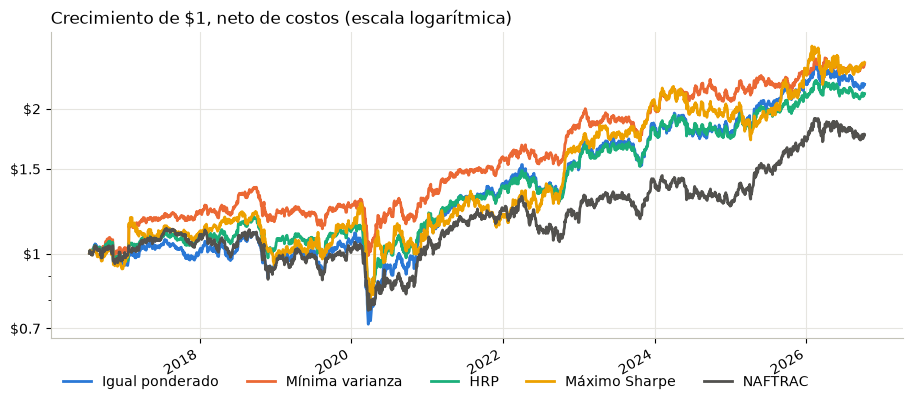

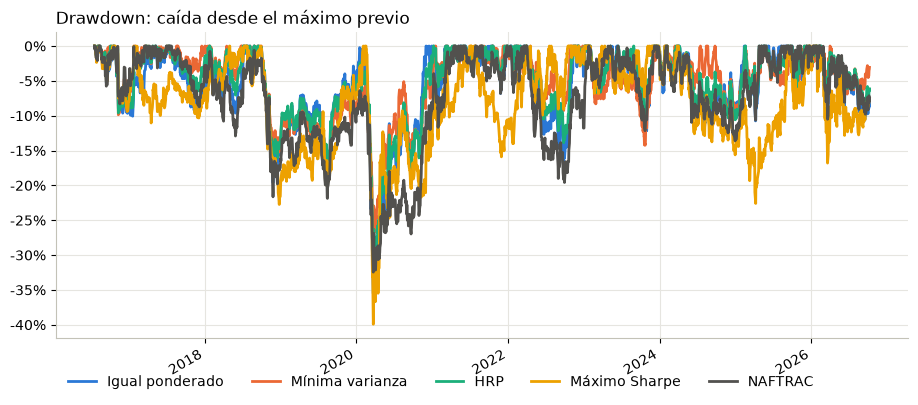

In [5]:
series = net[MAIN].join(bench)
plots.growth_chart(series, "Crecimiento de $1, neto de costos (escala logarítmica)")
plt.show()

plots.drawdown_chart(series, "Drawdown: caída desde el máximo previo")
plt.show()

**Comentarios:**
- **Puntos de separación:** Desde aproximadamente un año de operación el portafolio de mínima varianza se pone sobre el resto. A partir de ese punto se mantiene arriba y cae menos que los demás en el desplome de 2020. Finalmente, en el periodo 2025-2026 el portafolio de máximo Sharpe alcanza y supera ligeramente al de mínima varianza.
- **Marzo 2020:** Caen todas las estrategias; no se salvó ninguna, pero la de mínima varianza fue la menos afectada, registrando la caída menos abrupta. En periodos de crisis las correlaciones suben y la diversificación pierde parte de su efecto.
- **Estrategia de mayor protección:** La estrategia de mayor protección es la de mínima varianza y cumple con su cometido.

## 4. Concentración: en qué invierte cada estrategia

El **número efectivo de emisoras** es `1 / Σ w²`: vale 31 si todo está repartido por igual y 1 si todo está en una sola.

,N efectivo medio,Peso máximo medio,Emisoras con peso > 1% (media)
Igual ponderado,31.0,3.2%,31.0
Mínima varianza,10.2,18.3%,15.1
HRP,22.8,9.1%,29.9
Máximo Sharpe,5.4,31.7%,8.0
Máximo Sharpe (tope 15%),8.2,15.0%,9.9


,Mínima varianza,Máximo Sharpe,HRP
#1,AC.MX 10.7%,Q.MX 11.6%,AC.MX 6.1%
#2,FEMSAUBD.MX 9.3%,CHDRAUIB.MX 8.2%,FEMSAUBD.MX 5.7%
#3,GRUMAB.MX 8.1%,GCC.MX 7.4%,GRUMAB.MX 5.3%
#4,MEGACPO.MX 7.5%,GMEXICOB.MX 5.1%,MEGACPO.MX 5.2%
#5,GCC.MX 6.7%,LABB.MX 4.9%,WALMEX.MX 4.9%


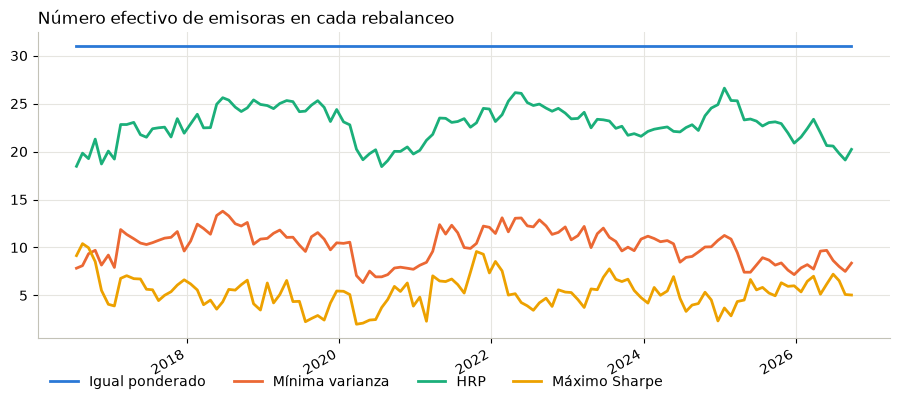

In [10]:
concentration = pd.DataFrame({
    name: {
        "N efectivo medio": (1 / (w**2).sum(axis=1)).mean(),
        "Peso máximo medio": w.max(axis=1).mean(),
        "Emisoras con peso > 1% (media)": (w > 0.01).sum(axis=1).mean(),
    }
    for name, w in weights.items()
}).T
display(concentration.style.format({"N efectivo medio": "{:.1f}", "Peso máximo medio": "{:.1%}", "Emisoras con peso > 1% (media)": "{:.1f}"}))

# Emisoras con mayor peso promedio en las dos estrategias optimizadas
top = pd.DataFrame({
    name: weights[name].mean().sort_values(ascending=False).head(5).map("{:.1%}".format).reset_index().agg(" ".join, axis=1)
    for name in ["Mínima varianza", "Máximo Sharpe","HRP"]
})
top.index = [f"#{i}" for i in range(1, 6)]
display(top)

n_eff = pd.DataFrame({name: 1 / (weights[name] ** 2).sum(axis=1) for name in MAIN})
ax = plots.line_chart(n_eff, "Número efectivo de emisoras en cada rebalanceo")
plt.show()

**Comentarios:**
**Concentración**
- **Mínima varianza:** Tiene en promedio 10 emisoras efectivas (15 con peso mayor a 1%) y su peso máximo promedia 18%. Tiene sentido que se concentre en las emisoras que muestran las varianzas más bajas en la ventana de estimación. Esa concentración no elimina el riesgo: que una emisora haya sido poco volátil el último año es una estimación, no una garantía, y el portafolio queda cargado en pocas emisoras parecidas (Arca, FEMSA y Gruma, de consumo básico). En esta muestra ese riesgo no se materializó.
- **Máximo Sharpe:** Tiene en promedio 5 emisoras efectivas y su peso máximo promedia 32%. Esto se explica por la tendencia a tomar las emisoras que muestran mejores retornos pasados. El riesgo en este caso aumenta considerablemente al depender de 5 emisoras: lo que pase con 1 o 2 tiene un gran peso en el portafolio completo. Esto explica que tenga la varianza más alta.
- **HRP:** Es la más diversificada de las tres estrategias optimizadas, con 23 emisoras efectivas en promedio, y la de menor peso máximo promedio (9%). Esto viene de la distribución jerárquica y el clustering del portafolio, que considera casi todas las emisoras.

## 5. Sensibilidad a los costos

El supuesto de 10 pb es optimista para un inversionista pequeño. Como los pesos no dependen del costo,
se puede recalcular el resultado con otros niveles sin volver a correr el backtest.

In [7]:
levels = [0, 10, 25, 50]
sharpe_by_cost = pd.DataFrame({
    f"{bps} pb": {name: metrics.sharpe_ratio(backtest.net_of_costs(gross[name], turnover[name], bps)) for name in STRATEGIES}
    for bps in levels
})
return_by_cost = pd.DataFrame({
    f"{bps} pb": {name: metrics.annualized_return(backtest.net_of_costs(gross[name], turnover[name], bps)) for name in STRATEGIES}
    for bps in levels
})
print(f"Referencia NAFTRAC: Sharpe {metrics.sharpe_ratio(bench):.2f}, retorno anual {metrics.annualized_return(bench):.1%}")
display(sharpe_by_cost.style.format("{:.2f}").set_caption("Sharpe según el costo por operación"))
display(return_by_cost.style.format("{:.1%}").set_caption("Retorno anual según el costo por operación"))

Referencia NAFTRAC: Sharpe 0.43, retorno anual 5.7%


,0 pb,10 pb,25 pb,50 pb
Igual ponderado,0.59,0.59,0.58,0.57
Mínima varianza,0.75,0.73,0.70,0.65
HRP,0.62,0.61,0.59,0.55
Máximo Sharpe,0.58,0.55,0.50,0.43
Máximo Sharpe (tope 15%),0.58,0.55,0.51,0.43


,0 pb,10 pb,25 pb,50 pb
Igual ponderado,8.3%,8.2%,8.1%,7.9%
Mínima varianza,9.6%,9.3%,8.8%,8.0%
HRP,8.0%,7.8%,7.5%,7.0%
Máximo Sharpe,10.0%,9.4%,8.4%,6.7%
Máximo Sharpe (tope 15%),8.7%,8.2%,7.4%,6.0%


**Comentarios:**
- **Mayor sensibilidad:** Máximo Sharpe resulta la estrategia más sensible a los cambios de costos; esto se debe a su alta rotación de activos durante el año, por lo que el costo aumenta mucho más que en los otros portafolios. Igual ponderado es el menos sensible, ya que tiene la menor rotación (32%); entre las estrategias optimizadas, la menos sensible es HRP.
- **Cambio de prioridades:** Con el aumento de 10 a 25 pb no hay un cambio tan importante en el Sharpe y el retorno anual de los portafolios, solo una disminución de ambos en proporción a la rotación de cada uno. Pasando a 50 pb, vemos cómo HRP supera a máximo Sharpe en retorno anual, lo que demuestra los diferentes niveles en los que este cambio los afecta. Pero mínima varianza se mantiene como la mejor estrategia.

## 6. Resultados por año y en el desplome de 2020

Un promedio de diez años puede esconder que la ventaja viene de uno o dos años.

In [8]:
by_year = (1 + series).groupby(series.index.year).prod() - 1
display(by_year.style.format("{:.1%}").set_caption("Retorno por año calendario (2016 y 2026 son años parciales)"))

wins = by_year[MAIN].gt(by_year["NAFTRAC"], axis=0).sum()
print("Años en que cada estrategia le ganó al NAFTRAC, de", len(by_year))
print(wins.to_string())

crash = series.loc["2020-02-20":"2020-04-30"]
crash_tbl = pd.DataFrame({"Retorno": (1 + crash).prod() - 1, "Max drawdown": crash.apply(metrics.max_drawdown)})
display(crash_tbl.style.format("{:.1%}").set_caption("Desplome por COVID-19: 20-feb a 30-abr de 2020"))

,Igual ponderado,Mínima varianza,HRP,Máximo Sharpe,NAFTRAC
Date,,,,,
2016,-3.4%,2.3%,-1.3%,-5.6%,-1.8%
2017,4.2%,19.3%,9.2%,17.0%,10.2%
2018,-6.9%,-3.2%,-5.2%,-13.2%,-13.9%
2019,11.5%,5.6%,8.6%,17.8%,7.9%
2020,9.9%,4.2%,4.4%,-3.4%,2.0%
2021,21.6%,22.2%,19.3%,10.1%,20.8%
2022,6.7%,14.7%,9.0%,36.0%,-6.3%
2023,24.6%,11.8%,20.7%,28.0%,22.3%
2024,-4.4%,3.0%,-3.8%,-9.7%,-10.3%


Años en que cada estrategia le ganó al NAFTRAC, de 11
Igual ponderado    7
Mínima varianza    8
HRP                6
Máximo Sharpe      7


,Retorno,Max drawdown
Igual ponderado,-20.2%,-32.8%
Mínima varianza,-11.9%,-23.0%
HRP,-17.3%,-29.2%
Máximo Sharpe,-15.2%,-39.2%
NAFTRAC,-18.4%,-26.3%


**Comentarios:**
- **Ventaja sobre NAFTRAC:** Los cuatro portafolios le ganan al NAFTRAC en más de la mitad de los años (6 de 11 en el peor caso y 8 de 11 en el mejor), pero la ventaja no es constante: las mayores diferencias se dan en los años en que el NAFTRAC cayó (2018, 2022 y 2024). En 2025, cuando el NAFTRAC subió 34.7%, los cuatro quedaron por debajo.
- **Menor desplome por COVID-19:** Aunque todas las estrategias fueron afectadas por el COVID-19, la que obtuvo menor desplome fue la de mínima varianza, con casi 12 puntos. En este caso podemos ver que mayor diversificación no necesariamente es la mejor estrategia para estos casos: igual ponderado reparte el capital entre las 31 emisoras y fue la que más cayó (−20.2%).

## 7. ¿La ventaja sobre el NAFTRAC es distinguible del azar?

Se mide el exceso de retorno diario de cada estrategia sobre el NAFTRAC. El *tracking error* es la volatilidad
de ese exceso, el *information ratio* es el exceso por unidad de tracking error, y el estadístico *t* indica si el
exceso promedio es distinto de cero (por regla general, |t| > 2).

In [9]:
active = net.sub(bench, axis=0)
significance = pd.DataFrame({
    "Exceso anual (aritmético)": active.mean() * TD,
    "Tracking error": active.std() * np.sqrt(TD),
    "Information ratio": active.mean() / active.std() * np.sqrt(TD),
    "t": active.mean() / active.std() * np.sqrt(len(active)),
})
significance.style.format({"Exceso anual (aritmético)": "{:.1%}", "Tracking error": "{:.1%}", "Information ratio": "{:.2f}", "t": "{:.2f}"})

,Exceso anual (aritmético),Tracking error,Information ratio,t
Igual ponderado,2.3%,6.7%,0.35,1.10
Mínima varianza,2.9%,10.3%,0.28,0.91
HRP,1.6%,7.4%,0.22,0.71
Máximo Sharpe,4.1%,16.1%,0.26,0.82
Máximo Sharpe (tope 15%),2.5%,11.7%,0.21,0.67


**Comentarios:**
- **Superan |t| > 2:** Ninguna estrategia supera el umbral (el t más alto es 1.10, el de igual ponderado), por lo que no se puede descartar que la ventaja sea producto de la suerte y no de una ventaja verdadera. Aunque esta ventaja sí puede existir, solo que no se puede confirmar.
- **No se puede afirmar que los portafolios le ganan al índice:** Con 10 años de datos la muestra no es suficiente y la diferencia no es estadísticamente significativa. Además, hace falta considerar el sesgo de supervivencia en los portafolios.

## 8. Advertencias metodológicas

- **Sesgo de supervivencia.** El universo es la muestra del IPC de sep-2026 aplicada desde 2015: todas las emisoras son
  ganadoras conocidas de antemano. Esto favorece a *todas* las estrategias frente al NAFTRAC, que sí cargó con las emisoras
  que después salieron del índice. La comparación entre estrategias es más confiable que la comparación contra el benchmark.
- **Sharpe con tasa libre de riesgo en cero.** Sirve para comparar estrategias entre sí; no mide el exceso sobre CETES,
  que en este periodo pagaron tasas altas.
- **Costos simplificados.** Un costo proporcional fijo no incluye impacto en precio ni diferenciales más amplios en emisoras poco líquidas.
- **Benchmark.** Al NAFTRAC le faltan unos 7 días por año en Yahoo Finance, que se rellenan con el precio anterior. No afecta
  su retorno acumulado, pero infla un poco el tracking error de la sección 7.
- **Un solo conjunto de parámetros.** Ventana de 252 días y rebalanceo mensual se fijaron de antemano. No se probaron
  alternativas para escoger la mejor, lo que sería sobreajustar el backtest.

## 9. Conclusiones del Bloque 2

- ¿Qué estrategia recomendarías y por qué? ¿Cuál descartarías?  
A partir de la muestra y de la configuración actual, la estrategia que muestra un rendimiento muy bueno emparejado con el menor riesgo y las menores caídas es la de mínima varianza, por lo que resulta el portafolio más completo. Descartaría los otros portafolios, pues considero que no tienen ninguna ventaja lo suficientemente importante sobre el de mínima varianza.
- ¿Por qué máximo Sharpe, que en teoría es la óptima, no resulta la mejor fuera de muestra?  
Considero que el principal motivo por el que máximo Sharpe pasó de ser la opción teórica óptima a la menos óptima en la prueba es que el optimizador hace bien su trabajo, pero no recibe muy buena información: los retornos esperados estimados con un año de datos son en su mayoría ruido. Mala información dentro -> mala información fuera. Limitar el peso por emisora a 15% no lo corrigió: el Sharpe quedó igual (0.55).
- ¿Qué gana y qué pierde HRP frente a mínima varianza?  
HRP destaca únicamente en el costo operacional y en tener menor rotación que el de mínima varianza. Por otro lado, también tiene una mayor diversificación (23 emisoras efectivas contra 10). Fuera de eso, es peor que el de mínima varianza en el resto de aspectos, desde retornos anuales hasta varianza o mayores bajadas.
- ¿Cuánto importan los costos y la rotación?  
Importan mucho; eso es lo que puede generar la diferencia entre que un portafolio sea rentable o no respecto a otro. Con el costo base de 10 pb, lo que se pierde al año va de 0.08% en igual ponderado a 0.67% en máximo Sharpe. Con costos de 50 pb, máximo Sharpe pierde más de 3 puntos anuales de retorno (de 10.0% a 6.7%).
- ¿Se puede afirmar que estas estrategias le ganan al NAFTRAC? ¿Con qué reservas?  
A primera vista, sí se podría afirmar que le ganan al NAFTRAC, pues muestran un mayor retorno y un mejor Sharpe. Pero si incluimos la posibilidad del azar en la ecuación, se deja de ver tan positivo, pues la diferencia no es suficiente para eliminar esa opción. Además, no es una comparación completamente equitativa: los portafolios tienen sesgo de supervivencia respecto al NAFTRAC. Considerando todo esto, no se puede afirmar que las estrategias sean mejores.